#Import libraries

In [1]:
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import IPython

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from tqdm import tqdm

# 2. Fetch the Dataset

*   ESC-50: a dataset for Environmental Sound Classification (https://github.com/karolpiczak/ESC-50, https://www.karolpiczak.com/papers/Piczak2015-ESC-Dataset.pdf)
 * 50 classes,  40 files per class, 5s clips
*   Download & unzip the dataset running the cell below. This will take a minute. You will see the new files on the left (folder icon).

In [2]:
!wget https://github.com/karolpiczak/ESC-50/archive/master.zip
!unzip master.zip
!rm master.zip

--2025-03-19 14:41:59--  https://github.com/karolpiczak/ESC-50/archive/master.zip
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master [following]
--2025-03-19 14:41:59--  https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master
Resolving codeload.github.com (codeload.github.com)... 140.82.114.9
Connecting to codeload.github.com (codeload.github.com)|140.82.114.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [application/zip]
Saving to: ‘master.zip’

master.zip              [              <=>   ] 615.78M  12.5MB/s    in 46s     

2025-03-19 14:42:46 (13.3 MB/s) - ‘master.zip’ saved [645695005]

Archive:  master.zip
33c8ce9eb2cf0b1c2f8bcf322eb349b6be34dbb6
   creating: ESC-50-master/
   creating: ESC-50-master/.circleci/
  inflating: ESC-50-ma

---

# 3. Metadata and analysis I

***Tasks:***
* Use pandas to read the csv file in *ESC-50-master/meta/*
* Print the first elements of the csv. Pandas has a standard function for this.
* Print the list of *unique* class labels in the dataset, and check whether there really are 50 of them

In [5]:
# Setup some filepaths
fn = 'ESC-50-master/meta/esc50.csv'

df = pd.read_csv(fn)
df.head()

unique_categories = np.unique(df['category'])
print(unique_categories)
print(len(unique_categories))

['airplane' 'breathing' 'brushing_teeth' 'can_opening' 'car_horn' 'cat'
 'chainsaw' 'chirping_birds' 'church_bells' 'clapping' 'clock_alarm'
 'clock_tick' 'coughing' 'cow' 'crackling_fire' 'crickets' 'crow'
 'crying_baby' 'dog' 'door_wood_creaks' 'door_wood_knock'
 'drinking_sipping' 'engine' 'fireworks' 'footsteps' 'frog'
 'glass_breaking' 'hand_saw' 'helicopter' 'hen' 'insects'
 'keyboard_typing' 'laughing' 'mouse_click' 'pig' 'pouring_water' 'rain'
 'rooster' 'sea_waves' 'sheep' 'siren' 'sneezing' 'snoring' 'thunderstorm'
 'toilet_flush' 'train' 'vacuum_cleaner' 'washing_machine' 'water_drops'
 'wind']
50


---

# 4. Metadata and analysis II

* View and listen to some examples in the dataset to get a "feeling" for the sound classes.

dog
chirping_birds
vacuum_cleaner


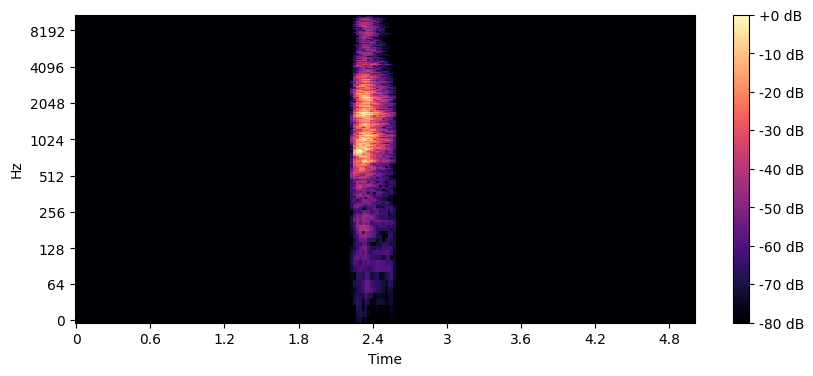

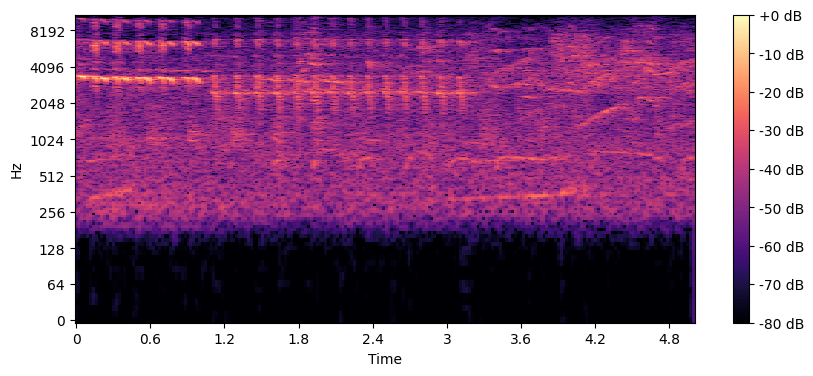

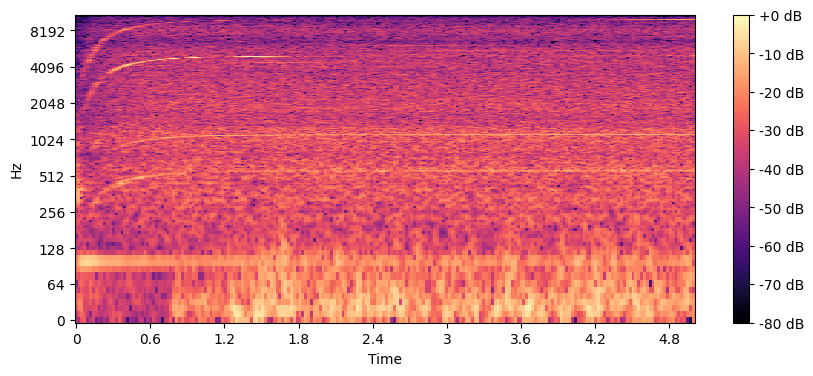

In [10]:
# Show audio player for each file
audio_path = 'ESC-50-master/audio/'
audio0 = audio_path + df['filename'][0]
audio1 = audio_path + df['filename'][1]
audio2 = audio_path + df['filename'][2]

print(df['category'][0])
print(df['category'][1])
print(df['category'][2])

IPython.display.display(IPython.display.Audio(audio0))
IPython.display.display(IPython.display.Audio(audio1))
IPython.display.display(IPython.display.Audio(audio2))

# Plot STFT specs
y0, sr0 = librosa.load(audio0)
D = librosa.amplitude_to_db(np.abs(librosa.stft(y0)), ref=np.max)
plt.figure(figsize=(10, 4))
librosa.display.specshow(D, sr=sr0, x_axis='time', y_axis='log')
plt.colorbar(format='%+2.0f dB')
plt.show()

y1, sr1 = librosa.load(audio1)
D = librosa.amplitude_to_db(np.abs(librosa.stft(y1)), ref=np.max)
plt.figure(figsize=(10, 4))
librosa.display.specshow(D, sr=sr1, x_axis='time', y_axis='log')
plt.colorbar(format='%+2.0f dB')
plt.show()

y2, sr2 = librosa.load(audio2)
D = librosa.amplitude_to_db(np.abs(librosa.stft(y2)), ref=np.max)
plt.figure(figsize=(10, 4))
librosa.display.specshow(D, sr=sr2, x_axis='time', y_axis='log')
plt.colorbar(format='%+2.0f dB')
plt.show()



---

# 5. ESC-5: Curation

Let's select 5 classes (*our_classes*) from ESC-50 to make things a bit faster.

***Tasks:***
* Collect all files that belong to *our_classes*.
* Put the files and their respective classes in separate lists. Make sure their indices are equal (meaning: the value at index 3 of list *A* is related to the value at index 3 of list *B*).
  * Idea 1: Use *df.values* to iterate over the rows of the csv
  * Idea 2: Use *df.query('category in @our_classes')*
* Print the first 5 elements of each list as (file, class)-tuples. Also, print the overall lengths of the lists.

In [15]:
#print(np.unique(df['category']))

selected_classes = ['crying_baby','dog','rain','rooster','sneezing']

esc5_files = []
esc5_classes = []

df2 = df.query('category in @selected_classes')
esc5_files = df2['filename'].values
esc5_classes = df2['category'].values

print(list(zip(esc5_files[:5], esc5_classes[:5])))
print(f'Lenght esc5_files: {len(esc5_files)}, Lenght esc5_classes: {len(esc5_classes)}')


[('1-100032-A-0.wav', 'dog'), ('1-110389-A-0.wav', 'dog'), ('1-17367-A-10.wav', 'rain'), ('1-187207-A-20.wav', 'crying_baby'), ('1-211527-A-20.wav', 'crying_baby')]
Lenght esc5_files: 200, Lenght esc5_classes: 200


---

# 6. ESC-5: Dataset splitting

***Tasks:***
* Split the dataset into *train* and *test* subsets: split ratio is 80%/20%, and random state 1337.
  * Use a suitable straight-forward function from sklearn.
* Print the first 3 elements of the resulting *X_train*.
* Print the overall lengths of the resulting lists. Are they aligned with the ratio?

Result: ESC-5 is ready. We have a train and test set consisting of file lists and their respective classes.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(esc5_files, esc5_classes,
                                                    train_size=0.8,
                                                    test_size=0.2, random_state=1337)

print(list(zip(X_train[:3], y_train[:3])))
print(f'Lenght X_train: {len(X_train)}, Lenght y_train: {len(y_train)}')
print(f'Lenght Y_test: {len(X_test)}, Lenght y_test: {len(y_test)}')


[('5-203128-A-0.wav', 'dog'), ('4-181286-A-10.wav', 'rain'), ('3-157615-A-10.wav', 'rain')]
Lenght X_train: 160, Lenght y_train: 160
Lenght Y_test: 40, Lenght y_test: 40


---
# 7. ESC-5: Create mel spectrograms

We need to compute features and corresponding labels for each file in our ESC-5.

***Tasks:***
* Define a function that does the following (in this order!):
  * takes input parameters: *X_train* (list of filenames), *y_train* (list of classes)
  * loops over *X_train* (hint: *enumerate* it), and loads each file (.wav) using librosa
  * creates the mel spectrogram from the loaded .wav samples
  * normalizes the mel spec by dividing it through the number of given *mel_bands*.
  * transposes the mel spec
  * appends the features (mel spec) to a feature tensor
  * creates a target vector consisting of as many values as there are frames
    * hint: use .shape to see which value you need
  * each value inside the vector must correspond to the index of the class in *our_classes*
    * hint: remember *numpy.ones(...)* ?
    * hint: use *.index(...)* here. Not ideal, but works here.
  * appends the targets to a target tensor
  * stacks the large feature and target lists appropriately
  * returns the tensors
* Finally, print the shapes of all 4 arrays.

In [50]:
def extract_mel_features(X_train, y_train):
  X = [] # X is the feature tensor
  y = []

  mel_bands = 128
  for i, file in enumerate(tqdm(X_train)):
    signal, sr = librosa.load(audio_path + file)
    mel_spec = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=mel_bands)
    mel_spec /= mel_bands
    mel_spec = mel_spec.T
    X.append(mel_spec) # X is the feature tensor

    # Categorical label
    y.append(np.ones(mel_spec.shape[0]) * selected_classes.index(y_train[i]))

  X = np.vstack(X) # Training Matrix
  y = np.hstack(y) # Vector

  return X, y

X_train_ready, y_train_ready = extract_mel_features(X_train, y_train)
X_test_ready, y_test_ready = extract_mel_features(X_test, y_test)




100%|██████████| 40/40 [00:00<00:00, 58.75it/s]


Shape X_train_ready: (34560, 128)
Shape y_train_ready: (34560,)
Shape X_test_ready: (8640, 128)
Shape y_test_ready: (8640,)


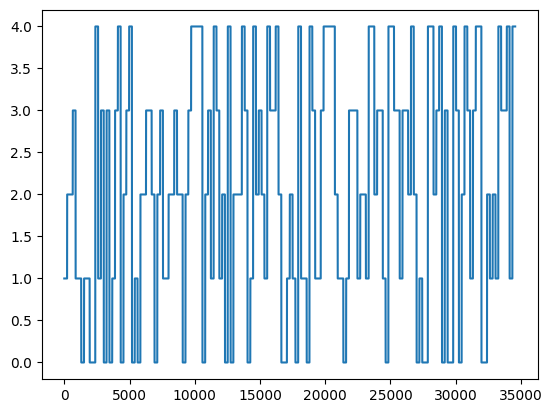

In [51]:
print(f'Shape X_train_ready: {X_train_ready.shape}')
print(f'Shape y_train_ready: {y_train_ready.shape}')
print(f'Shape X_test_ready: {X_test_ready.shape}')
print(f'Shape y_test_ready: {y_test_ready.shape}')

plt.plot(y_train_ready)

In [52]:
np.isnan(X_train_ready)

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

---

# 8. ESC-5: Train a nearest neighbor classifier

***Tasks:***
* Standardize the features from step 7 using sklearn.
* Use the features and targets to train (*fit*) a kNN-classifier from sklearn, with 5 neighbors and uniform weighting.
* Print the scores on the train set and test set, rounded to 4 decimals. (This will take some time!)


In [53]:
print('Scaling ...')
scaler = StandardScaler()
scaler.fit(X_train_ready)

X_train_scaled = scaler.transform(X_train_ready)
X_test_scaled = scaler.transform(X_test_ready)

Scaling ...


In [55]:
print('Classification ...')
knn = KNeighborsClassifier(n_neighbors=5, weights='uniform')
knn.fit(X_train_scaled, y_train_ready)

print('Evaluation')
print(f'Train score: {np.round(knn.score(X_train_scaled, y_train_ready), decimals=4)}')
print(f'Test score: {np.round(knn.score(X_test_scaled, y_test_ready), decimals=4)}')

Classification ...
Evaluation
Train score: 0.7648
Test score: 0.5781


---

# 9. ESC-5: Plot the confusion matrix
We want to learn more about our classifier. How well does it perform per class?

***Tasks:***
* Using scikit-learn, create a confusion matrix of our classifier over the test set
* Normalize the rows, use 'our_classes' as axes tick values
* Display the plot

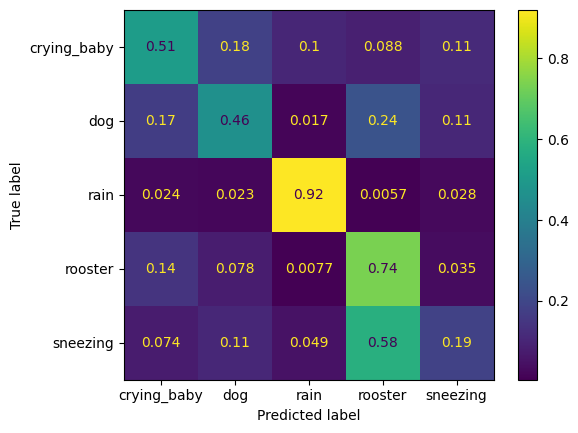

In [57]:
cm = confusion_matrix(y_true=y_test_ready, y_pred=knn.predict(X_test_scaled), normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=selected_classes)
disp.plot()
plt.show()
